##Part 1



** 1.**

Business Problem
The company wants to understand why customers leave and which customers are more likely to churn. The target variable is Churn, which shows whether a customer left or stayed.


** 2.**



 Useful predictors

Contract Customers:with shorter contracts may be more likely to leave.
tenure: Customers who have been with the company for a short time may churn more.
MonthlyCharges: Higher monthly bills might make customers leave.
InternetService :The type of internet service may affect customer satisfaction.
PaymentMethod : Some payment methods may be linked to higher churn.



 useless predictors
customerID: It only identifies the customer and does not explain their behavior.
gender:It may not have a strong connection with whether a customer leaves.


** 3.**



 Q1:


 Do month-to-month customers churn more?



 Q2:



Do higher monthly charges lead to more churn?




In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn
df=pd.read_csv('/content/drive/MyDrive/Dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv')



##Part 2
Exploring  Dataset Structure


Task 4_Data set size and features type

In [7]:
df.shape


(7043, 21)

In [8]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [9]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


Task 4 Answer

The Dataset contain 7043 customers and 21 columns

Numerical feautures
tenure
monthly charges
total charges
senior citizen


Categorical Features
gender
partner
contract
churn
internet service
dependents



As I identified these categories by examining the data types and the meaning of each column.

Task 5

specifying the Identifier and Wrong data type

In [13]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [14]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [17]:
df['TotalCharges'].head(20)
df['TotalCharges'].unique()[:20]
pd.to_numeric(df['TotalCharges'], errors='coerce').isna().sum()



np.int64(11)

Task 5 Answer
`customerID` is an identifier rather than a predictive feature. It uniquely identifies each customer, but the ID itself does not describe a meaningful customer characteristic that would help explain customer churn.


`TotalCharges` has an `object` data type, even though it represents the total amount charged to a customer and should therefore be numerical. I investigated this column using `head()`, `unique()`, and `pd.to_numeric()` to check whether it contains values that prevent it from being stored as a numeric column.



Task 6

Unique Values of Categorical columns

In [20]:
df['gender'].unique()
df['gender'].value_counts()

,count
gender,
Male,3555
Female,3488


1. Gender

The unique values
- Female
- Male

These categories are consistent.

In [22]:
df['Contract'].unique()
df['Contract'].value_counts()

,count
Contract,
Month-to-month,3875
Two year,1695
One year,1473


2. Contract

The unique values
- Month-to-month
- One year
- Two year

These categories are consistent and represent the different contract types available to customers.

In [24]:
df['InternetService'].unique()
df['InternetService'].value_counts()

,count
InternetService,
Fiber optic,3096
DSL,2421
No,1526


3.InternetService

The unique values
- DSL
- Fiber optic
- No

These categories are consistent and represent the available internet service options.
No unexpected or inconsistently formatted category was observed.

##Part 3 — Investigating Data Quality


Task 7 — Missing Values

In [25]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [26]:
(df.isnull().mean() * 100).round(2)

,0
customerID,0.0
gender,0.0
SeniorCitizen,0.0
Partner,0.0
Dependents,0.0
tenure,0.0
PhoneService,0.0
MultipleLines,0.0
InternetService,0.0
OnlineSecurity,0.0


In [27]:
missing_report = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().mean() * 100).round(2)
})

missing_report

,Missing Count,Missing Percentage
customerID,0,0.0
gender,0,0.0
SeniorCitizen,0,0.0
Partner,0,0.0
Dependents,0,0.0
tenure,0,0.0
PhoneService,0,0.0
MultipleLines,0,0.0
InternetService,0,0.0
OnlineSecurity,0,0.0


Task 7 — Answer

The missing-value analysis shows that all columns have 0 missing values and a missing percentage of 0.0%.

There are no missing-value problems that require action in this dataset.

Task 8 — Duplicate Rows and Duplicate Customer Ids

In [30]:
df.duplicated().sum()

np.int64(0)

In [29]:
df['customerID'].duplicated().sum()

np.int64(0)

Task 8 — Answer

The dataset contains 0 completely duplicated rows and 0 duplicated customer IDs

Task 9 — Suspicious, Invalid Values

In [31]:
df['TotalCharges'].dtype

dtype('O')

In [33]:
df['TotalCharges'].head(20)
df['TotalCharges'].unique()[:20]

array(['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5',
       '1949.4', '301.9', '3046.05', '3487.95', '587.45', '326.8',
       '5681.1', '5036.3', '2686.05', '7895.15', '1022.95', '7382.25',
       '528.35', '1862.9'], dtype=object)

In [34]:
totalcharges_numeric = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

totalcharges_numeric.isna().sum()

np.int64(11)

In [35]:
df.loc[
    totalcharges_numeric.isna(),
    ['customerID', 'tenure', 'TotalCharges']
]

,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


Task 9 — Answer

I investigated the TotalCharges column because it is stored as an object data type even though it represents a numerical billing amount

The conversion identified 11 problematic values.

These are suspicious data-quality values because TotalCharges represents a numerical billing amount but these entries are blank. Therefore, they need to be handled during the data-cleaning stage before the dataset is used.

##Part 4 — Data Cleaning Decisions


Task 10 — Data Quality Decisions


| Problem | Decision | Method Used | Reason |
|---|---|---|---|
| No missing values were detected | No action | No cleaning required | All columns have 0 missing values and 0.0% missing values. |
| No duplicate customer IDs were found | No action | No duplicate IDs removed | Every `customerID` is unique, so there is no duplicate ID problem. |
| No duplicate rows were found | No action | No duplicate rows removed | No completely duplicated records were found. |
| `TotalCharges` contains 11 blank/non-numeric values and is stored as `object` | Convert `TotalCharges` to numeric and remove the affected rows | `pd.to_numeric(..., errors='coerce')` followed by removing rows with missing `TotalCharges` | `TotalCharges` represents a numerical billing amount. The 11 problematic records have `tenure = 0`, and the number of affected records is very small, so removing them avoids inventing charge values. |

Task 11 — Apply Cleaning Decisions

In [38]:
cleaned_df = df.copy()

In [39]:
cleaned_df['TotalCharges'] = pd.to_numeric(
    cleaned_df['TotalCharges'],
    errors='coerce'
)

In [40]:
cleaned_df['TotalCharges'].dtype

dtype('float64')

In [41]:
cleaned_df = cleaned_df.dropna(subset=['TotalCharges'])

In [42]:
cleaned_df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [43]:
cleaned_df['customerID'].duplicated().sum()

np.int64(0)

In [44]:
pd.to_numeric(cleaned_df['TotalCharges'], errors='coerce').isna().sum()

np.int64(0)

In [45]:
cleaned_df.shape

(7032, 21)

##Part 5 — Univariate EDA

Task 12

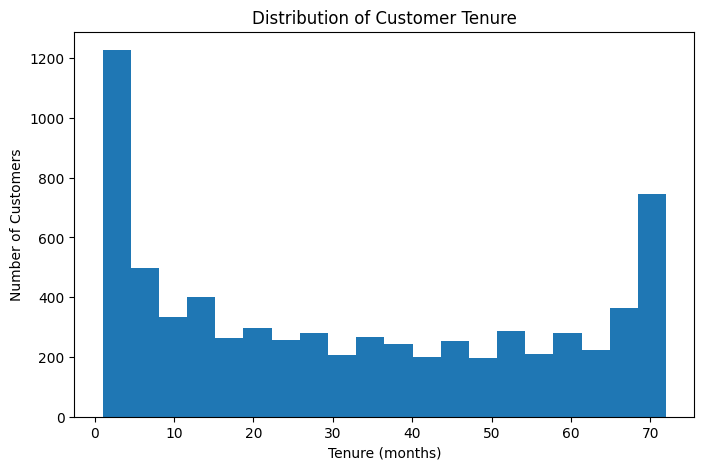

In [46]:
plt.figure(figsize=(8,5))

plt.hist(cleaned_df['tenure'], bins=20)

plt.title('Distribution of Customer Tenure')
plt.xlabel('Tenure (months)')
plt.ylabel('Number of Customers')

plt.show()

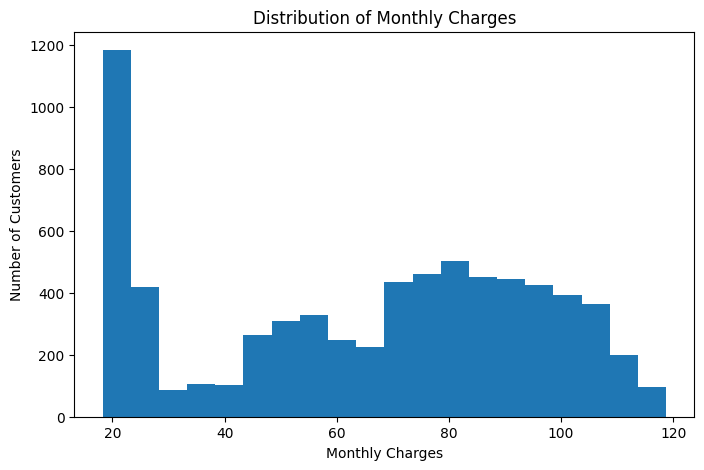

In [47]:
plt.figure(figsize=(8,5))

plt.hist(cleaned_df['MonthlyCharges'], bins=20)

plt.title('Distribution of Monthly Charges')
plt.xlabel('Monthly Charges')
plt.ylabel('Number of Customers')

plt.show()

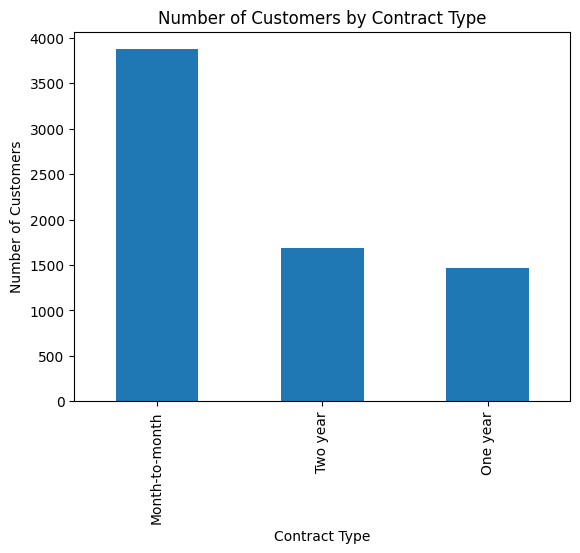

In [48]:
cleaned_df['Contract'].value_counts().plot(kind='bar')

plt.title('Number of Customers by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.show()

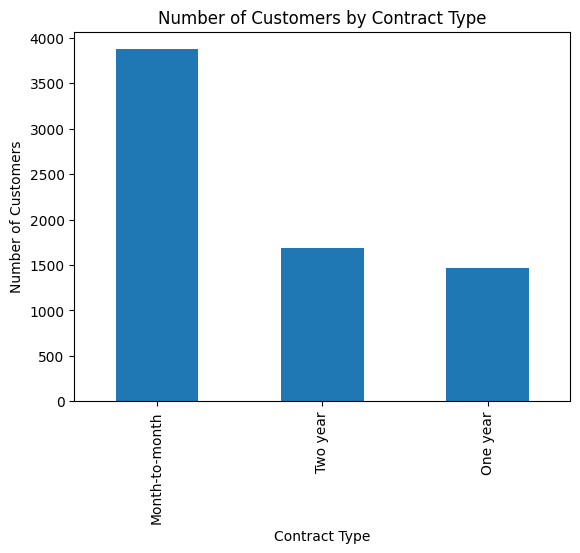

In [49]:
cleaned_df['Contract'].value_counts().plot(kind='bar')

plt.title('Number of Customers by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.show()

Task 13

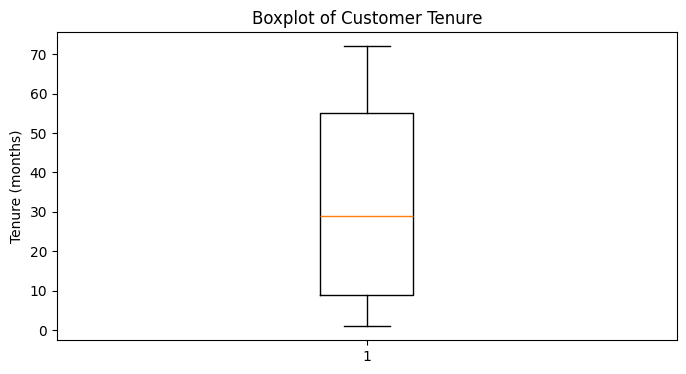

In [50]:
plt.figure(figsize=(8,4))

plt.boxplot(cleaned_df['tenure'])

plt.title('Boxplot of Customer Tenure')
plt.ylabel('Tenure (months)')

plt.show()

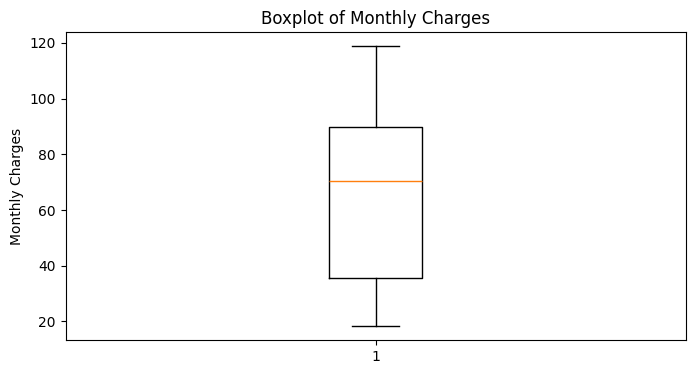

In [51]:
plt.figure(figsize=(8,4))

plt.boxplot(cleaned_df['MonthlyCharges'])

plt.title('Boxplot of Monthly Charges')
plt.ylabel('Monthly Charges')

plt.show()

In [53]:
cleaned_df[['tenure', 'MonthlyCharges']].skew()

,0
tenure,0.237731
MonthlyCharges,-0.222103


In [54]:
Q1 = cleaned_df[['tenure', 'MonthlyCharges']].quantile(0.25)
Q3 = cleaned_df[['tenure', 'MonthlyCharges']].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bounds:")
print(lower_bound)

print("\nUpper bounds:")
print(upper_bound)

Lower bounds:
tenure           -60.000
MonthlyCharges   -45.825
dtype: float64

Upper bounds:
tenure            124.000
MonthlyCharges    171.275
dtype: float64


In [55]:
outlier_counts = (
    (cleaned_df[['tenure', 'MonthlyCharges']] < lower_bound) |
    (cleaned_df[['tenure', 'MonthlyCharges']] > upper_bound)
).sum()

outlier_counts

,0
tenure,0
MonthlyCharges,0


Task 13 answer

I examined the numerical features tenure and MonthlyCharges using histograms, boxplots, skewness, and the IQR method.

##Part 6

Task 14

In [56]:
cleaned_df['Churn'].value_counts()

,count
Churn,
No,5163
Yes,1869


In [57]:
cleaned_df['Churn'].value_counts(normalize=True).mul(100).round(2)

,proportion
Churn,
No,73.42
Yes,26.58


In [58]:
churn_report = pd.DataFrame({
    'Count': cleaned_df['Churn'].value_counts(),
    'Percentage': cleaned_df['Churn'].value_counts(normalize=True).mul(100).round(2)
})

churn_report

,Count,Percentage
Churn,,
No,5163,73.42
Yes,1869,26.58


Task 15
Class imbalance matters because a classification model may learn more from the majority class than the minority class.

In this dataset, the model may perform well at predicting non-churned customers but may be less effective at identifying customers who actually churn.

##Part 7 — Bivariate Analysis: Features vs. Churn


Task 16

In [60]:
pd.crosstab(
    cleaned_df['Contract'],
    cleaned_df['Churn']
)

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1306,166
Two year,1637,48


In [61]:
contract_churn = pd.crosstab(
    cleaned_df['Contract'],
    cleaned_df['Churn'],
    normalize='index'
).mul(100).round(2)

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.72,11.28
Two year,97.15,2.85


In [63]:
pd.crosstab(
    cleaned_df['InternetService'],
    cleaned_df['Churn']
)
internet_churn = pd.crosstab(
    cleaned_df['InternetService'],
    cleaned_df['Churn'],
    normalize='index'
).mul(100).round(2)

internet_churn

Churn,No,Yes
InternetService,,
DSL,81.00,19.00
Fiber optic,58.11,41.89
No,92.57,7.43


Task 16 table

| Feature | Observation | Evidence | Possible Explanation |
|---|---|---|---|
| Contract | Month-to-month customers have the highest churn, while two-year contract customers have the lowest churn. | Month-to-month churn = 42.71%, one-year = 11.28%, and two-year = 2.85%. | Customers with shorter contracts may have less commitment and may be more likely to leave. |
| InternetService | Fiber optic customers have a higher churn rate than DSL and customers with no internet service. | Fiber optic churn = 41.89%, DSL = 19.00%, and No Internet Service = 7.43%. | The difference may be related to service experience, pricing, or customer expectations. |

Task 17



In [64]:
cleaned_df.groupby('Churn')['tenure'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).round(2)

,count,mean,median,min,max
Churn,,,,,
No,5163,37.65,38.0,1,72
Yes,1869,17.98,10.0,1,72


In [65]:
cleaned_df.groupby('Churn')['MonthlyCharges'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).round(2)

,count,mean,median,min,max
Churn,,,,,
No,5163,61.31,64.45,18.25,118.75
Yes,1869,74.44,79.65,18.85,118.35


Task 17 answer
###

| Feature | Observation | Evidence | Possible Explanation |
|---|---|---|---|
| Tenure | Churned customers have shorter tenure. | Mean: 17.98 vs 37.65 months. | Newer customers may be more likely to leave. |
| MonthlyCharges | Churned customers have higher charges. | Mean: 74.44 vs 61.31. | Higher charges may be related to higher churn. |

##Part 8 — Correlation & Feature Relationships


Task 18

In [66]:
numerical_features = cleaned_df.select_dtypes(include='number')

correlation_matrix = numerical_features.corr()

correlation_matrix

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000000,0.015683,0.219874,0.102411
tenure,0.015683,1.000000,0.246862,0.825880
MonthlyCharges,0.219874,0.246862,1.000000,0.651065
TotalCharges,0.102411,0.825880,0.651065,1.000000


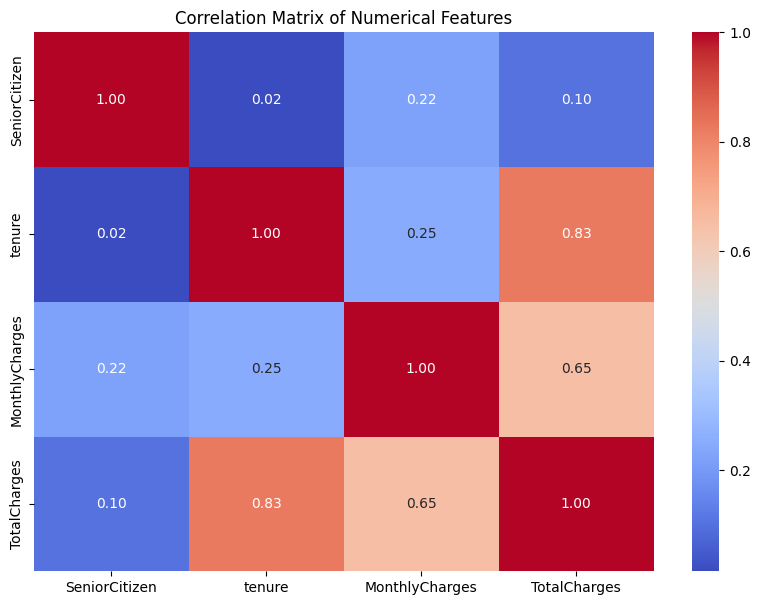

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000000,0.015683,0.219874,0.102411
tenure,0.015683,1.000000,0.246862,0.825880
MonthlyCharges,0.219874,0.246862,1.000000,0.651065
TotalCharges,0.102411,0.825880,0.651065,1.000000


In [68]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Matrix of Numerical Features')
plt.show()
correlation_matrix

Task 19


Correlation does not imply causation, so a strong relationship between two features does not mean that one causes the other. Highly correlated features may provide similar information to a future model and can make it harder to interpret the model's individual feature effects.

##Part 9 — Data Leakage Awareness


 Task 20

`customerID` is a suspect because it is only used to identify customers and does not give us any useful information about their behavior.

`Churn` should also not be used as an input feature because it is the outcome we are trying to predict.

Task 21 — Why This Matters

If we include `Churn` or any information that is only known after churn, the model could get information about the answer in advance and give unrealistically good results. Using `customerID` could also make the model learn meaningless patterns instead of useful information about customers.

##Part 11 — Building the Clean Dataset


Task 23

In [72]:
clean_df = cleaned_df.copy()
clean_df = clean_df.drop(columns=['customerID'])
clean_df['TotalCharges'] = pd.to_numeric(
    clean_df['TotalCharges'],

    errors='coerce'
)
clean_df.isnull().sum()
clean_df.to_csv('clean_churn.csv', index=False)


import os
print(os.path.exists('clean_churn.csv'))


True


Task 24

In [73]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   object 
 1   SeniorCitizen     7032 non-null   int64  
 2   Partner           7032 non-null   object 
 3   Dependents        7032 non-null   object 
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   object 
 6   MultipleLines     7032 non-null   object 
 7   InternetService   7032 non-null   object 
 8   OnlineSecurity    7032 non-null   object 
 9   OnlineBackup      7032 non-null   object 
 10  DeviceProtection  7032 non-null   object 
 11  TechSupport       7032 non-null   object 
 12  StreamingTV       7032 non-null   object 
 13  StreamingMovies   7032 non-null   object 
 14  Contract          7032 non-null   object 
 15  PaperlessBilling  7032 non-null   object 
 16  PaymentMethod     7032 non-null   object 
 17  

##Part 12 — Key Findings & Final Reflection


Task 25



 Finding 1
Observation: `TotalCharges` had 11 blank values.  
Evidence: All 11 had `tenure = 0`.  
Interpretation: These values needed to be cleaned before ML.




 Finding 2
Observation:Month-to-month customers churned more.  
Evidence: Churn was 42.71% compared with 11.28% for one-year and 2.85% for two-year contracts.  
Interpretation: Shorter contracts seem more likely to churn.





 Finding 3
Observation: Churned customers had shorter tenure.  
Evidence: Mean tenure was 17.98 vs 37.65 months.  
Interpretation: Newer customers seem more likely to leave.




 Finding 4
Observation: Churned customers had higher monthly charges.  
Evidence: Mean was 74.44 vs 61.31.  
Interpretation:Higher charges may be related to churn.




 Finding 5
Observation:`tenure` and `TotalCharges` were strongly related.  
Evidence: Correlation was 0.826.  
Interpretation:Longer-tenure customers usually have higher total charges.

Task 26

1. **Most important issue:** 11 blank values were found in TotalCharges.

2. **Most interesting pattern:** Month-to-month customers had much higher churn.

3. **Most useful feature:** Contract seems useful for predicting churn.

4. **Feature not to use:** customerID, because it is only an identifier.

5. **Preprocessing needed:** Convert categorical data into numerical form before ML.

6. **Next step:** Train and compare a few classification models.
